In [4]:
# Ćelija 1: Instalacija paketa (pokrenuti jednom po sesiji)
!pip install -q monai nibabel

In [2]:
# Ćelija 2: Uvoz modula i postavljanje okruženja
import os
import glob
import random
import numpy as np
import nibabel as nib
import torch
from torch.utils.data import Dataset, DataLoader

from monai.networks.nets import SegResNet
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference
from monai.transforms import (
    Compose,
    RandSpatialCropd,
    RandFlipd,
    RandRotate90d,
    EnsureTyped,
)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("Koristi se uređaj:", device)

I0000 00:00:1795526964.620191      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Koristi se uređaj: cuda:0


In [3]:
# Ćelija 3: Konfiguracija putanja i hiperparametara
BASE_DIR = "/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation"
DATA_TRAIN_GLOB = f"{BASE_DIR}/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_*"
DATA_TEST_GLOB = f"{BASE_DIR}/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData/BraTS20_Validation_*"

SAVE_DIR = "/kaggle/working/checkpoints"
PRED_DIR = "/kaggle/working/predictions"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)

PATCH_SIZE = (64, 64, 64)   # povećati na (128, 128, 128) ako ima slobodnog VRAM-a
BATCH_SIZE = 4
SW_BATCH_SIZE = 8
EPOCHS = 21
LR = 1e-4
WEIGHT_DECAY = 1e-5
PATIENCE = 4                # early stopping nakon 4 epohe bez napretka
MIN_DELTA = 1e-4
NUM_CLASSES = 4             # 0: pozadina, 1: NCR/NET, 2: ED, 3: ET (mapirano iz 4)

In [4]:
# Ćelija 4: Dataset klasa i transformacije
class BraTS3DDataset(Dataset):
    def __init__(self, case_dirs, transforms=None):
        self.case_dirs = case_dirs
        self.transforms = transforms

    def __len__(self):
        return len(self.case_dirs)

    @staticmethod
    def _load_nifti(path):
        return nib.load(path).get_fdata().astype(np.float32)

    def _find_modality(self, case_dir, mod):
        matches = sorted(glob.glob(os.path.join(case_dir, f"*_{mod}.nii*")))
        if not matches:
            raise FileNotFoundError(f"Nedostaje modalitet '{mod}' u {case_dir}")
        return matches[0]

    def _find_seg(self, case_dir):
        matches = sorted(
            glob.glob(os.path.join(case_dir, "*_seg.nii*"))
            + glob.glob(os.path.join(case_dir, "*Segm*.nii*"))
        )
        if not matches:
            raise FileNotFoundError(f"Nedostaje maska segmentacije u {case_dir}")
        return matches[0]

    def __getitem__(self, idx):
        d = self.case_dirs[idx]
        modalities = ["t1", "t1ce", "t2", "flair"]
        chans = []

        for m in modalities:
            img_path = self._find_modality(d, m)
            img = self._load_nifti(img_path)
            mask_nz = img > 0
            if np.any(mask_nz):
                mean = img[mask_nz].mean()
                std = img[mask_nz].std() + 1e-8
                img = np.where(mask_nz, (img - mean) / std, 0.0)
            chans.append(img)

        image = np.stack(chans, axis=0)  # (4, H, W, D)
        seg_path = self._find_seg(d)
        seg = self._load_nifti(seg_path).astype(np.int64)
        seg[seg == 4] = 3
        label = seg[None, ...]  # (1, H, W, D)

        sample = {"image": image, "label": label}
        if self.transforms:
            sample = self.transforms(sample)
        return sample


train_transforms = Compose([
    RandSpatialCropd(keys=["image", "label"], roi_size=PATCH_SIZE, random_size=False),
    RandFlipd(keys=["image", "label"], prob=0.2, spatial_axis=0),
    RandFlipd(keys=["image", "label"], prob=0.2, spatial_axis=1),
    RandFlipd(keys=["image", "label"], prob=0.1, spatial_axis=2),
    RandRotate90d(keys=["image", "label"], prob=0.2, spatial_axes=(0, 1)),
    EnsureTyped(keys=["image", "label"], track_meta=False),
])

# Validacija radi nad cijelim 3D volumenima putem sliding_window_inference
val_transforms = Compose([
    EnsureTyped(keys=["image", "label"], track_meta=False),
])

all_cases = sorted(glob.glob(DATA_TRAIN_GLOB))
assert len(all_cases) > 0, "Nije pronađen nijedan slučaj — provjerite DATA_TRAIN_GLOB putanju!"

valid_cases = []
skipped_cases = []

for c in all_cases:
    has_seg = bool(
        glob.glob(os.path.join(c, "*_seg.nii*"))
        or glob.glob(os.path.join(c, "*Segm*.nii*"))
    )
    if has_seg:
        valid_cases.append(c)
    else:
        skipped_cases.append(os.path.basename(c))

assert len(valid_cases) > 0, "Nijedan slučaj nema masku segmentacije!"
if skipped_cases:
    print(f"Preskočeni slučajevi bez maske: {skipped_cases}")

split_idx = int(0.8 * len(valid_cases))
train_ds = BraTS3DDataset(valid_cases[:split_idx], transforms=train_transforms)
val_ds = BraTS3DDataset(valid_cases[split_idx:], transforms=val_transforms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=0, pin_memory=True)
print(f"Trening slučajeva: {len(train_ds)} | Validacijskih slučajeva: {len(val_ds)}")

Trening slučajeva: 295 | Validacijskih slučajeva: 74


In [ ]:
# Ćelija 5. Provjera random slučaja, gif prikaz lokacije tumora
import os, glob
import numpy as np
import nibabel as nib
from PIL import Image
from IPython.display import Image as IPImage, display

# 1. Uzmi prvi dostupan slučaj (ili zamijeni indeks / path po želji)
sample_case = train_cases[0] if "train_cases" in globals() and len(train_cases) > 0 else sorted(glob.glob("/kaggle/input/**/BraTS20_Training_*", recursive=True))[0]
case_id = os.path.basename(sample_case)
print("Provjeravam slučaj:", case_id)

modalities = ["flair", "t1ce", "t1", "t2"]
vols = {}

for m in modalities:
    matches = sorted(glob.glob(os.path.join(sample_case, f"*_{m}.nii*")))
    assert len(matches) > 0, f"Nije pronađen modalitet {m} u {sample_case}"
    img_data = nib.load(matches[0]).get_fdata().astype(np.float32)
    # Normalizacija po nenultim vokselima (standardno za MRI)
    mask_nz = img_data > 0
    if np.any(mask_nz):
        mean_val = img_data[mask_nz].mean()
        std_val = img_data[mask_nz].std()
        norm_data = np.zeros_like(img_data)
        norm_data[mask_nz] = (img_data[mask_nz] - mean_val) / (std_val + 1e-8)
    else:
        norm_data = img_data
    # Skaliranje u 0..255 za prikaz
    p_low, p_high = np.percentile(norm_data[mask_nz], [1, 99]) if np.any(mask_nz) else (0.0, 1.0)
    vis = np.clip((norm_data - p_low) / (p_high - p_low + 1e-8), 0.0, 1.0) * 255.0
    vols[m] = vis.astype(np.uint8)
    print(f"  {m:4s}: shape={img_data.shape}, min={img_data.min():.1f}, max={img_data.max():.1f}")

# 2. Učitaj masku ako postoji
seg_matches = sorted(glob.glob(os.path.join(sample_case, "*_seg.nii*")))
seg_vol = nib.load(seg_matches[0]).get_fdata().astype(np.uint8) if seg_matches else None
if seg_vol is not None:
    print(f"  seg : shape={seg_vol.shape}, klase={np.unique(seg_vol)}")

# 3. Generiraj GIF kroz aksijalne (Z) rezove (2x2 mreža modaliteta + preklapanje tumora)
depth = vols["flair"].shape[2]
frames = []

for z in range(0, depth, 2):  # svaki 2. rez da GIF bude brz i kompaktan
    # Sastavi 2x2 grid: [FLAIR, T1ce; T1, T2]
    top_row = np.hstack([vols["flair"][:, :, z], vols["t1ce"][:, :, z]])
    bot_row = np.hstack([vols["t1"][:, :, z], vols["t2"][:, :, z]])
    grid_gray = np.vstack([top_row, bot_row])

    # Rotiraj da mozak stoji uspravno u slici
    grid_gray = np.rot90(grid_gray)
    rgb = np.stack([grid_gray, grid_gray, grid_gray], axis=-1).astype(np.float32)

    if seg_vol is not None:
        seg_slice = np.rot90(seg_vol[:, :, z])
        seg_grid = np.vstack([
            np.hstack([seg_slice, seg_slice]),
            np.hstack([seg_slice, seg_slice]),
        ])
        tumor_mask = seg_grid > 0
        # Lagani crveni/žuti overlay na regijama tumora
        rgb[tumor_mask, 0] = np.clip(rgb[tumor_mask, 0] * 0.5 + 125.0, 0, 255)
        rgb[tumor_mask, 1] = np.clip(rgb[tumor_mask, 1] * 0.7, 0, 255)
        rgb[tumor_mask, 2] = np.clip(rgb[tumor_mask, 2] * 0.7, 0, 255)

    frames.append(Image.fromarray(rgb.astype(np.uint8)))

gif_path = os.path.join("/kaggle/working", f"{case_id}_brain_preview.gif")
frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=90,  # ms po frameu
    loop=0,
)
print("GIF spremljen u:", gif_path)
display(IPImage(filename=gif_path))

In [5]:
# Ćelija 6: Inicijalizacija SegResNet modela, funkcije gubitka i optimizatora
model = SegResNet(
    spatial_dims=3,
    init_filters=16,
    in_channels=4,
    out_channels=NUM_CLASSES,
    dropout_prob=0.2,
).to(device)

loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda")
dice_metric = DiceMetric(include_background=False, reduction="mean")

In [6]:
# Ćelija 7: Treniranje modela
import os, time
import torch
from tqdm.auto import tqdm

VAL_INTERVAL = 3

os.makedirs(SAVE_DIR, exist_ok=True)
best_model_path = os.path.join(SAVE_DIR, "best_segresnet.pt")
last_ckpt_path = os.path.join(SAVE_DIR, "last_checkpoint.pt")

best_dice = -1.0
epochs_no_improve = 0
train_start_all = time.time()

for epoch in range(1, EPOCHS + 1):
    t_start = time.time()
    torch.cuda.reset_peak_memory_stats(device)

    model.train()
    train_loss = 0.0

    pbar = tqdm(
        enumerate(train_loader, start=1),
        total=len(train_loader),
        desc=f"Epoha {epoch:02d}/{EPOCHS:02d} [Train]",
        leave=True,
    )

    for step, batch in pbar:
        imgs = batch["image"].to(device, non_blocking=True)
        lbls = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            preds = model(imgs)
            loss = loss_fn(preds, lbls)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        loss_val = loss.item()
        train_loss += loss_val

        elapsed_ep = time.time() - t_start
        eta_ep = (elapsed_ep / step) * (len(train_loader) - step)
        avg_ep_time = (time.time() - train_start_all) / epoch
        eta_total_min = (avg_ep_time * (EPOCHS - epoch) + eta_ep) / 60.0
        vram_gb = torch.cuda.max_memory_allocated(device) / (1024 ** 3)

        pbar.set_postfix({
            "loss": f"{loss_val:.4f}",
            "avg": f"{train_loss / step:.4f}",
            "eta_ep": f"{eta_ep:.0f}s",
            "eta_all": f"{eta_total_min:.1f}m",
            "VRAM": f"{vram_gb:.2f}G",
        })

    pbar.close()
    train_loss /= max(len(train_loader), 1)

    # Periodični checkpoint za nastavak treninga ako sesija stane
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_dice": best_dice,
    }, last_ckpt_path)

    if epoch % VAL_INTERVAL == 0 or epoch == EPOCHS:
        model.eval()
        dice_metric.reset()
        with torch.no_grad():
            for batch in tqdm(
                val_loader,
                total=len(val_loader),
                desc=f"Epoha {epoch:02d}/{EPOCHS:02d} [Val]",
                leave=False,
            ):
                imgs = batch["image"].to(device, non_blocking=True)
                lbls = batch["label"].to(device, non_blocking=True)

                with torch.amp.autocast("cuda", dtype=torch.float16):
                    preds = sliding_window_inference(
                        inputs=imgs,
                        roi_size=PATCH_SIZE,
                        sw_batch_size=SW_BATCH_SIZE,
                        predictor=model,
                        overlap=0.5,
                        mode="gaussian",
                    )

                pred_cls = torch.argmax(preds, dim=1)
                pred_onehot = torch.nn.functional.one_hot(pred_cls, num_classes=NUM_CLASSES).permute(0, 4, 1, 2, 3).float()
                lbl_onehot = torch.nn.functional.one_hot(lbls.squeeze(1), num_classes=NUM_CLASSES).permute(0, 4, 1, 2, 3).float()
                dice_metric(y_pred=pred_onehot, y=lbl_onehot)

        val_dice = dice_metric.aggregate().item()
        elapsed = time.time() - t_start
        peak_vram = torch.cuda.max_memory_allocated(device) / (1024 ** 3)

        print(
            f"--> Epoha {epoch:02d}/{EPOCHS:02d} gotova za {elapsed:.1f}s | "
            f"Train Loss: {train_loss:.4f} | 3D Val Dice: {val_dice:.4f} | Peak VRAM: {peak_vram:.2f} GB",
            flush=True,
        )

        if val_dice > best_dice + MIN_DELTA:
            best_dice = val_dice
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_model_path)
            print(f"  -> Novi najbolji model spremljen ({best_dice:.4f})", flush=True)
        else:
            epochs_no_improve += 1
            print(f"  -> Nema poboljšanja ({epochs_no_improve}/{PATIENCE})", flush=True)
            if epochs_no_improve >= PATIENCE:
                print(f"Early stopping u epohi {epoch}. Najbolji 3D Val Dice: {best_dice:.4f}", flush=True)
                break
    else:
        elapsed = time.time() - t_start
        peak_vram = torch.cuda.max_memory_allocated(device) / (1024 ** 3)
        print(
            f"--> Epoha {epoch:02d}/{EPOCHS:02d} gotova za {elapsed:.1f}s | "
            f"Train Loss: {train_loss:.4f} | Val preskočena | Peak VRAM: {peak_vram:.2f} GB",
            flush=True,
        )

Epoha 01/21 [Train]:   0%|          | 0/74 [00:00<?, ?it/s]

--> Epoha 01/21 gotova za 782.5s | Train Loss: 2.1278 | Val preskočena | Peak VRAM: 1.34 GB


Epoha 02/21 [Train]:   0%|          | 0/74 [00:00<?, ?it/s]

--> Epoha 02/21 gotova za 396.9s | Train Loss: 1.9892 | Val preskočena | Peak VRAM: 1.34 GB


Epoha 03/21 [Train]:   0%|          | 0/74 [00:00<?, ?it/s]

Epoha 03/21 [Val]:   0%|          | 0/74 [00:00<?, ?it/s]

... (39 outputs left out)

--> Epoha 20/21 gotova za 689.2s | Train Loss: 0.9665 | Val preskočena | Peak VRAM: 1.67 GB


Epoha 21/21 [Train]:   0%|          | 0/74 [00:00<?, ?it/s]

Epoha 21/21 [Val]:   0%|          | 0/74 [00:00<?, ?it/s]

--> Epoha 21/21 gotova za 966.6s | Train Loss: 0.9501 | 3D Val Dice: 0.2337 | Peak VRAM: 1.67 GB
  -> Nema poboljšanja (4/4)
Early stopping u epohi 21. Najbolji 3D Val Dice: 0.4603


Best model 3D Val Dice: 0.4603


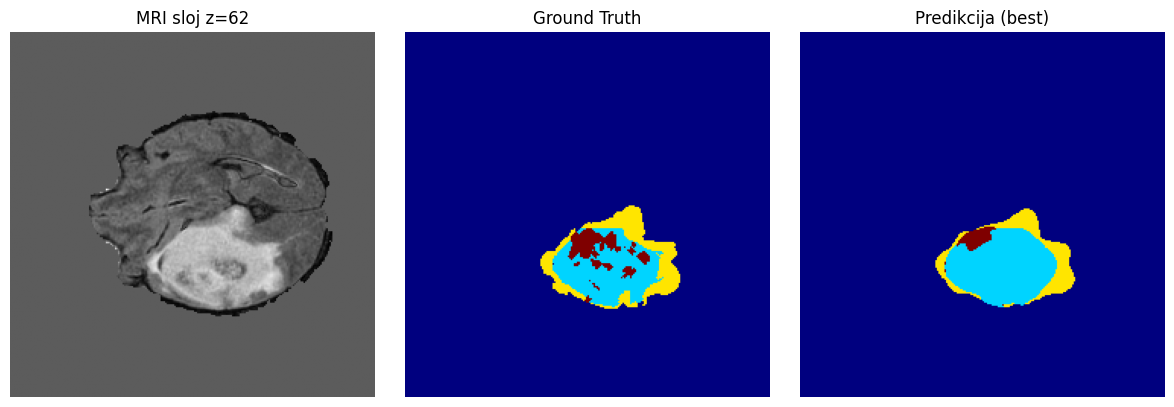

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()
dice_metric.reset()

sample_img, sample_lbl, sample_pred = None, None, None

with torch.no_grad():
    for idx, batch in enumerate(val_loader):
        imgs = batch["image"].to(device, non_blocking=True)
        lbls = batch["label"].to(device, non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            preds = sliding_window_inference(
                inputs=imgs,
                roi_size=PATCH_SIZE,
                sw_batch_size=SW_BATCH_SIZE,
                predictor=model,
                overlap=0.5,
                mode="gaussian",
            )

        pred_cls = torch.argmax(preds, dim=1)
        pred_onehot = torch.nn.functional.one_hot(pred_cls, num_classes=NUM_CLASSES).permute(0, 4, 1, 2, 3).float()
        lbl_onehot = torch.nn.functional.one_hot(lbls.squeeze(1), num_classes=NUM_CLASSES).permute(0, 4, 1, 2, 3).float()
        dice_metric(y_pred=pred_onehot, y=lbl_onehot)

        if idx == 0:
            sample_img = imgs[0, 3].cpu().numpy()      # npr. FLAIR kanal
            sample_lbl = lbls[0, 0].cpu().numpy()
            sample_pred = pred_cls[0].cpu().numpy()

mean_dice = dice_metric.aggregate().item()
print(f"Best model 3D Val Dice: {mean_dice:.4f}")

# Prikaz sloja s najvećim brojem tumorskih voksela
z_best = int(np.argmax((sample_lbl > 0).sum(axis=(0, 1))))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sample_img[:, :, z_best], cmap="gray")
axes[0].set_title(f"MRI sloj z={z_best}")
axes[1].imshow(sample_lbl[:, :, z_best], vmin=0, vmax=3, cmap="jet")
axes[1].set_title("Ground Truth")
axes[2].imshow(sample_pred[:, :, z_best], vmin=0, vmax=3, cmap="jet")
axes[2].set_title("Predikcija (best)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [17]:
# Celija 8. Inferencija na novom slucaju i spremnaje segmentacije
from pathlib import Path

import nibabel as nib
import numpy as np
import torch
from monai.inferers import sliding_window_inference
from monai.networks.nets import SegResNet

# ---------------- 1. KONFIGURACIJA ----------------
BASE_DIR = Path("/kaggle/input/datasets/tomislavurekovi/testiranje1")
MODEL_PATH = BASE_DIR / "best_segresnet.pt"
CASE_DIR = BASE_DIR / "test1/test1"
PRED_DIR = Path("/kaggle/working/preds")
PRED_DIR.mkdir(parents=True, exist_ok=True)

PATCH_SIZE = (64, 64, 64)
SW_BATCH_SIZE = 8
INIT_FILTERS = 16
IN_CHANNELS = 4
OUT_CHANNELS = 4  # NUM_CLASSES = 4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- 2. UČITAVANJE MODELA ----------------
model = SegResNet(
    spatial_dims=3,
    init_filters=INIT_FILTERS,
    in_channels=IN_CHANNELS,
    out_channels=OUT_CHANNELS,
    dropout_prob=0.2,
).to(device)

loaded = torch.load(MODEL_PATH, map_location=device, weights_only=False)
if isinstance(loaded, dict):
    state_dict = loaded.get("model_state_dict") or loaded.get("state_dict") or loaded
else:
    state_dict = loaded

cleaned_state_dict = {
    (k[7:] if k.startswith("module.") else k): v
    for k, v in state_dict.items()
}

model.load_state_dict(cleaned_state_dict)
model.eval()
print(f"Model učitan iz '{MODEL_PATH}' na uređaj: {device}")


# ---------------- 3. UČITAVANJE I NORMALIZACIJA FOLDERA ----------------
def _find_modality_in_dir(case_dir: Path, mod: str) -> str:
    target_suffix = f"_{mod.lower()}.nii"
    nii_files = sorted(
        p
        for p in case_dir.iterdir()
        if p.is_file() and p.name.lower().endswith(".nii")
    )
    for p in nii_files:
        if p.name.lower().endswith(target_suffix):
            return str(p)

    raise FileNotFoundError(
        f"Nedostaje datoteka sa sufiksom '{target_suffix}' u '{case_dir}'. "
        f"Pronađene .nii datoteke: {[p.name for p in nii_files]}"
    )


def load_and_normalize_folder(case_dir: Path):
    if not case_dir.is_dir():
        raise FileNotFoundError(f"Folder ne postoji: {case_dir}")

    cid = case_dir.resolve().name
    modalities = ["t1", "t1ce", "t2", "flair"]
    chans = []
    ref_nii = None

    for m in modalities:
        mod_path = _find_modality_in_dir(case_dir, m)
        nii = nib.load(mod_path)
        if ref_nii is None:
            ref_nii = nii
        img = nii.get_fdata().astype(np.float32)
        mask_nz = img > 0
        if np.any(mask_nz):
            img = np.where(mask_nz, (img - img[mask_nz].mean()) / (img[mask_nz].std() + 1e-8), 0.0)
        chans.append(img)

    tensor = torch.from_numpy(np.stack(chans, axis=0)[None, ...])  # (1, 4, H, W, D)
    return cid, tensor, ref_nii.affine, ref_nii.header


# ---------------- 4. INFERENCIJA I SPREMANJE ----------------
with torch.no_grad():
    cid, imgs, affine, header = load_and_normalize_folder(CASE_DIR)
    imgs = imgs.to(device, non_blocking=True)

    if device.type == "cuda":
        with torch.amp.autocast("cuda", dtype=torch.float16):
            logits = sliding_window_inference(
                inputs=imgs,
                roi_size=PATCH_SIZE,
                sw_batch_size=SW_BATCH_SIZE,
                predictor=model,
                overlap=0.5,
                mode="gaussian",
            )
    else:
        logits = sliding_window_inference(
            inputs=imgs,
            roi_size=PATCH_SIZE,
            sw_batch_size=2,
            predictor=model,
            overlap=0.5,
            mode="gaussian",
        )

    pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)
    pred_mask[pred_mask == 3] = 4

    out_file = PRED_DIR / "_seg.nii.gz"
    out_img = nib.Nifti1Image(pred_mask, affine=affine, header=header)
    out_img.set_data_dtype(np.uint8)
    nib.save(out_img, str(out_file))

print(f"Inferencija gotova. Maska spremljena u: {out_file}")

Model učitan iz '/kaggle/input/datasets/tomislavurekovi/testiranje1/best_segresnet.pt' na uređaj: cuda
Inferencija gotova. Maska spremljena u: /kaggle/working/preds/_seg.nii.gz


In [7]:
#  kod za provjeru da li se stvorio fajl sa istreniranim težinama
import os, glob

print("Trenutni radni direktorij:", os.getcwd())
print("Sve .pt datoteke u /kaggle/working:")
for p in sorted(glob.glob("/kaggle/working/**/*.pt", recursive=True)):
    print(" ", p, f"({os.path.getsize(p)/(1024**2):.2f} MB)")


Trenutni radni direktorij: /kaggle/working
Sve .pt datoteke u /kaggle/working:
  /kaggle/working/checkpoints/best_segresnet.pt (17.97 MB)
  /kaggle/working/checkpoints/last_checkpoint.pt (53.91 MB)


In [8]:
# kod za skidanje istreniranih težina

!zip -j /kaggle/working/model_export.zip /kaggle/working/checkpoints/best_segresnet.pt

  adding: best_segresnet.pt (deflated 8%)
